In [61]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings
warnings.filterwarnings("ignore")
pd.pandas.set_option("display.max_columns" , None)

df = pd.read_csv("EasyVisa.csv")
print(df.shape)

(25480, 12)


## **DATA CLEANING**

In [62]:
# Handling missing values
features_with_na = [feature for feature in df.columns if df[feature].isnull().sum() >= 1]
features_with_na if len(features_with_na) > 0 else "No missing values"

'No missing values'

In [63]:
# Handling the duplicates 
df.duplicated().sum()

0

In [64]:
# Remove case_id from the dataset
df.drop('case_id' , inplace = True , axis = 1)

## **FEATURE EXTRACTION**

In [65]:
df.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [66]:
from datetime import date 
todays_date = date.today()
current_year = todays_date.year
current_year

2026

In [67]:
# Substract current year from company eastablishment date
df['company_age'] = current_year - df['yr_of_estab']
df.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status,company_age
0,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied,19
1,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified,24
2,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied,18
3,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied,129
4,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified,21


In [68]:
df.drop('yr_of_estab' , inplace=True , axis = 1)

In [69]:
# Type of Features
num_features = [feature for feature in df.columns if df[feature].dtype != 'O']
print("Num of Numerical Features : " , len(num_features))

cat_features = [feature for feature in df.columns if df[feature].dtype == 'O']
print("Num of Categorical Features : " , len(cat_features))

Num of Numerical Features :  3
Num of Categorical Features :  8


In [70]:
discrete_features = [feature for feature in df.columns if len(df[feature].unique()) <= 25]
print("Number of Discrete Features : " , len(discrete_features))

continuour_feature = [feature for feature in df.columns if len(df[feature].unique()) > 25]
print("Number of Continuous Features : " , len(continuour_feature))

Number of Discrete Features :  8
Number of Continuous Features :  3


### **X & Y Split**

In [71]:
X = df.drop('case_status' , axis = 1)
y = df['case_status']

In [72]:
y.head()

0       Denied
1    Certified
2       Denied
3       Denied
4    Certified
Name: case_status, dtype: object

### **Encoding**

In [73]:
y = np.where(y == "Denied" , 1 , 0)

In [74]:
y

array([1, 0, 1, ..., 0, 0, 0])

### **Skewness**

In [75]:
# Check Skewness
# Positively Skewed  company_age , no_of_employees
X[continuour_feature].skew(axis = 0 , skipna = True)

no_of_employees    12.265260
prevailing_wage     0.755776
company_age         2.037301
dtype: float64

In [76]:
# Apply Power transformer to check skewness and reduce outliers
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method="yeo-johnson")
transform_feature = ['company_age' , 'no_of_employees']
X_copy = pt.fit_transform(X[transform_feature])

In [77]:
X_copy = pd.DataFrame(X_copy , columns=transform_feature)

In [78]:
X_copy.skew(axis = 0 , skipna=True)

company_age        0.120823
no_of_employees    0.399339
dtype: float64

## **Pre-Processing**

In [79]:
num_features = list(X.select_dtypes(exclude="object").columns)

In [80]:
num_features

['no_of_employees', 'prevailing_wage', 'company_age']

In [81]:
or_columns = ['has_job_experience' , 'requires_job_training' , 'full_time_position' , 'education_of_employee']
oh_columns = ['continent' , 'unit_of_wage' , 'region_of_employment']
transform_columns = ['no_of_employees' , 'company_age']

from sklearn.preprocessing import OneHotEncoder, StandardScaler , OrdinalEncoder , PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numerica_transformer = StandardScaler()
oh_transformer = OneHotEncoder()
ordinal_encoder = OrdinalEncoder()

transformer_pipe = Pipeline(steps=[
    ('transformer' , PowerTransformer(method="yeo-johnson"))
])

preprocessor = ColumnTransformer(
    [
        ('OneHotEncoder' , oh_transformer , oh_columns),
        ('Ordinal_Encoder' , ordinal_encoder , or_columns),
        ('Transformer' , transformer_pipe , transform_columns),
        ('StandardScaler' , numerica_transformer , num_features)
    ]
)


In [82]:
X = preprocessor.fit_transform(X)

## **CLASSIFICATION**

In [83]:
from imblearn.combine import SMOTETomek , SMOTEENN

smt = SMOTEENN(random_state=42 , sampling_strategy='minority')
X_res , y_res = smt.fit_resample(X,y)

## **Train Test Split**

In [84]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(X_res , y_res , random_state=42 , test_size=0.2)
X_train.shape , X_test.shape 

((13644, 24), (3412, 24))

In [85]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier , GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC 
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, precision_score , recall_score , f1_score, roc_auc_score , roc_curve
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

In [86]:
def evaluate_clf(true , predicted):
    acc = accuracy_score(true , predicted)
    f1 = f1_score(true , predicted)
    precision = precision_score(true , predicted)
    recall = recall_score(true , predicted)
    roc_auc = roc_auc_score(true , predicted)
    return acc , f1 , precision , recall , roc_auc 

In [87]:
models = {
    "Random Forest" : RandomForestClassifier(),
    "Decision Tree" : DecisionTreeClassifier(),
    "Gradient Boosting" : GradientBoostingClassifier(),
    "Logistic Regression" : LogisticRegression(),
    "K-Neighbors Classifier" : KNeighborsClassifier(),
    "XGBClassifier" : XGBClassifier(),
    "CatBoosting Classifier" : CatBoostClassifier(verbose = False),
    "Support Vector Classifier" : SVC(),
    "AdaBoost Classifier" : AdaBoostClassifier()
}

In [91]:
def evaluate_models(X, y, models):
    '''
    This function takes in X and y and models dictionary as input
    It splits the data into Train Test split
    Iterates through the given model dictionary and evaluates the metrics
    Returns: Dataframe which contains report of all models metrics with cost
    '''
    # separate dataset into train and test
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
    
    models_list = []
    accuracy_list = []
    auc= []
    
    for i in range(len(list(models))):
        model = list(models.values())[i]
        model.fit(X_train, y_train) # Train model

        # Make predictions
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)

        # Training set performance
        model_train_accuracy, model_train_f1,model_train_precision,\
        model_train_recall,model_train_rocauc_score=evaluate_clf(y_train ,y_train_pred)


        # Test set performance
        model_test_accuracy,model_test_f1,model_test_precision,\
        model_test_recall,model_test_rocauc_score=evaluate_clf(y_test, y_test_pred)

        print(list(models.keys())[i])
        models_list.append(list(models.keys())[i])

        print('Model performance for Training set')
        print("- Accuracy: {:.4f}".format(model_train_accuracy))
        print('- F1 score: {:.4f}'.format(model_train_f1)) 
        print('- Precision: {:.4f}'.format(model_train_precision))
        print('- Recall: {:.4f}'.format(model_train_recall))
        print('- Roc Auc Score: {:.4f}'.format(model_train_rocauc_score))

        print('----------------------------------')

        print('Model performance for Test set')
        print('- Accuracy: {:.4f}'.format(model_test_accuracy))
        accuracy_list.append(model_test_accuracy)
        print('- F1 score: {:.4f}'.format(model_test_f1))
        print('- Precision: {:.4f}'.format(model_test_precision))
        print('- Recall: {:.4f}'.format(model_test_recall))
        print('- Roc Auc Score: {:.4f}'.format(model_test_rocauc_score))
        auc.append(model_test_rocauc_score)
        print('='*35)
        print('\n')
        
    report=pd.DataFrame(list(zip(models_list, accuracy_list)), columns=['Model Name', 'Accuracy']).sort_values(by=['Accuracy'], ascending=False)
        
    return report

In [92]:
base_model_report = evaluate_models(X=X_res , y = y_res , models = models )

Random Forest
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for Test set
- Accuracy: 0.9552
- F1 score: 0.9585
- Precision: 0.9598
- Recall: 0.9572
- Roc Auc Score: 0.9550


Decision Tree
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for Test set
- Accuracy: 0.9232
- F1 score: 0.9287
- Precision: 0.9333
- Recall: 0.9242
- Roc Auc Score: 0.9231


Gradient Boosting
Model performance for Training set
- Accuracy: 0.8860
- F1 score: 0.8944
- Precision: 0.8941
- Recall: 0.8946
- Roc Auc Score: 0.8852
----------------------------------
Model performance for Test set
- Accuracy: 0.8933
- F1 score: 0.9011
- Precision: 0.9040
- Recall: 0.8982
- Roc Auc Score: 0.8929


Logistic Regression
Model performance for Training 

In [93]:
base_model_report

,Model Name,Accuracy
0,Random Forest,0.955158
4,K-Neighbors Classifier,0.941090
5,XGBClassifier,0.936401
6,CatBoosting Classifier,0.928195
1,Decision Tree,0.923212
2,Gradient Boosting,0.893318
7,Support Vector Classifier,0.873681
8,AdaBoost Classifier,0.860785
3,Logistic Regression,0.737104


### **Hyper Parameter Tuning**

In [94]:
#Initialize few parameter for Hyperparamter tuning
xgboost_params = {
    'max_depth':range(3,10,2),
    'min_child_weight':range(1,6,2)
}

rf_params = {
    "max_depth": [10, 12, None, 15, 20],
    "max_features": ['sqrt', 'log2', None],
    "n_estimators": [10, 50, 100, 200]
}

knn_params = {
    "algorithm": ['auto', 'ball_tree', 'kd_tree','brute'],
    "weights": ['uniform', 'distance'],
    "n_neighbors": [3, 4, 5, 7, 9],
}

In [95]:
randomcv_models = [
    ('XGBoost', XGBClassifier(), xgboost_params),
    ("RF", RandomForestClassifier(), rf_params),
    ("KNN", KNeighborsClassifier(), knn_params)
]

In [96]:
from sklearn.model_selection import RandomizedSearchCV

model_param = {}
for name, model, params in randomcv_models:
    random = RandomizedSearchCV(estimator=model,
                                   param_distributions=params,
                                   n_iter=100,
                                   cv=3,
                                   verbose=2, 
                                   n_jobs=-1)
    random.fit(X_res, y_res)
    model_param[name] = random.best_params_

for model_name in model_param:
    print(f"---------------- Best Params for {model_name} -------------------")
    print(model_param[model_name])

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Fitting 3 folds for each of 60 candidates, totalling 180 fits
Fitting 3 folds for each of 40 candidates, totalling 120 fits
---------------- Best Params for XGBoost -------------------
{'min_child_weight': 1, 'max_depth': 9}
---------------- Best Params for RF -------------------
{'n_estimators': 100, 'max_features': 'log2', 'max_depth': None}
---------------- Best Params for KNN -------------------
{'weights': 'distance', 'n_neighbors': 4, 'algorithm': 'auto'}


In [97]:
model_param

{'XGBoost': {'min_child_weight': 1, 'max_depth': 9},
 'RF': {'n_estimators': 100, 'max_features': 'log2', 'max_depth': None},
 'KNN': {'weights': 'distance', 'n_neighbors': 4, 'algorithm': 'auto'}}

In [98]:
from sklearn.metrics import roc_auc_score,roc_curve
best_models = {
    "Random Forest Classifier": RandomForestClassifier(**model_param['RF']),
    "KNeighborsClassifier": KNeighborsClassifier(**model_param['KNN']),
    "XGBClassifier": XGBClassifier(**model_param['XGBoost'],n_jobs=-1),
}
tuned_report =evaluate_models(X=X_res, y=y_res, models=best_models)

Random Forest Classifier
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for Test set
- Accuracy: 0.9546
- F1 score: 0.9579
- Precision: 0.9608
- Recall: 0.9550
- Roc Auc Score: 0.9545


KNeighborsClassifier
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for Test set
- Accuracy: 0.9719
- F1 score: 0.9743
- Precision: 0.9620
- Recall: 0.9870
- Roc Auc Score: 0.9705


XGBClassifier
Model performance for Training set
- Accuracy: 0.9994
- F1 score: 0.9995
- Precision: 0.9993
- Recall: 0.9996
- Roc Auc Score: 0.9994
----------------------------------
Model performance for Test set
- Accuracy: 0.9461
- F1 score: 0.9501
- Precision: 0.9521
- Recall: 0.9480
- Roc Auc Score: 0.9459




In [99]:
tuned_report

,Model Name,Accuracy
1,KNeighborsClassifier,0.971864
0,Random Forest Classifier,0.954572
2,XGBClassifier,0.946073


In [100]:
best_model = KNeighborsClassifier(**model_param['KNN'])
best_model = best_model.fit(X_train,y_train)
y_pred = best_model.predict(X_test)
score = accuracy_score(y_test,y_pred)
cr = classification_report(y_test,y_pred)

print("FINAL MODEL 'KNN'")
print ("Accuracy Score value: {:.4f}".format(score))
print (cr)

FINAL MODEL 'KNN'
Accuracy Score value: 0.9719
              precision    recall  f1-score   support

           0       0.98      0.95      0.97      1566
           1       0.96      0.99      0.97      1846

    accuracy                           0.97      3412
   macro avg       0.97      0.97      0.97      3412
weighted avg       0.97      0.97      0.97      3412



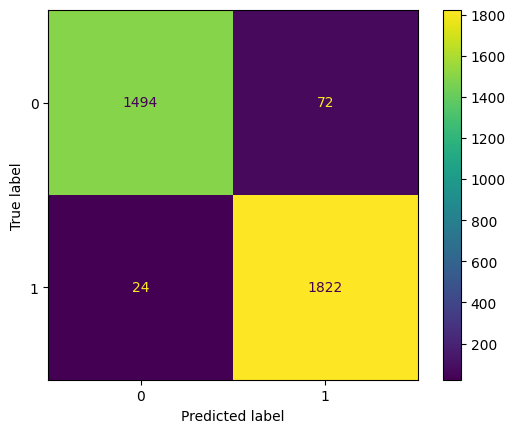

In [101]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test)

In [102]:
y_prob = best_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9894513213478731
